# RunBugRun: EDA 

Официальный источник: [giganticode/run_bug_run](https://github.com/giganticode/run_bug_run).

## Подготовка (один из вариантов)

1. Скачать с [giganticode/run_bug_run/releases](https://github.com/giganticode/run_bug_run/releases/tag/v2) runbugrun.sql.lrz и распаковать (инструкция также лежит в README.md репозитория runbugrun): 
```bash
sudo apt-get install lrzip sqlite3
lrunzip -z runbugrun.sql.lrz
sqlite3 runbugrun.db < runbugrun.sql
```
2. В следующей ячейке укажите **реальный путь** к `runbugrun.db`. Хранить большую базу лучше **вне Git-репозитория**.

Официальные значения в схеме: `bugs.language = 5` — Python, `bugs.split`: `0` train, `1` valid, `2` test, `3` unfiltered. Примеры могут быть неактивными (`active = 0`).

In [ ]:
import os
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", 120)

# Измените на свой путь.
# Либо задайте переменную окружения RUNBUGRUN_DB.
your_path = r""
DB_PATH = Path(os.environ.get("RUNBUGRUN_DB", your_path))
DB_PATH = DB_PATH.expanduser().resolve()
assert DB_PATH.is_file(), f"Не найдена SQLite-база: {DB_PATH}. Нужен runbugrun.db"

# Читаем базу только для анализа; notebook ничего в ней не изменит.
conn = sqlite3.connect(DB_PATH.as_uri() + "?mode=ro", uri=True)
conn.execute("PRAGMA query_only = ON")
print(f"База: {DB_PATH}\nРазмер: {DB_PATH.stat().st_size / 1024**3:.2f} ГиБ")

## 1. Таблицы и схема: сверяем реальную базу с документацией

In [2]:
tables = pd.read_sql_query(
    """SELECT name FROM sqlite_master
    WHERE type = 'table' AND name NOT LIKE 'sqlite_%'
    ORDER BY name""",
    conn,
)
display(tables)

for table in ("bugs", "problems", "tests"):
    print(f"\nСхема {table}:")
    display(
        pd.read_sql_query(f"PRAGMA table_info({table})", conn)[
            ["name", "type", "notnull", "pk"]
        ]
    )

,name
0,ar_internal_metadata
1,bugs
2,evaluations
3,problems
4,runs
5,schema_migrations
6,tests



Схема bugs:


,name,type,notnull,pk
0,id,INTEGER,1,1
1,buggy_code,TEXT,1,0
2,fixed_code,TEXT,1,0
3,problem_id,varchar,1,0
4,user_id,varchar,1,0
5,buggy_submission_id,varchar,1,0
6,fixed_submission_id,varchar,1,0
7,language,INTEGER,1,0
8,label_ids,json,0,0
9,runtime_errors,json,0,0



Схема problems:


,name,type,notnull,pk
0,id,INTEGER,1,1
1,problem_id,varchar,0,0
2,text,TEXT,0,0
3,similar_problems,jsonb,0,0



Схема tests:


,name,type,notnull,pk
0,id,INTEGER,1,1
1,problem_id,varchar,1,0
2,test_id,INTEGER,1,0
3,input,TEXT,0,0
4,output,TEXT,0,0
5,created_at,datetime(6),1,0
6,updated_at,datetime(6),1,0
7,origin,INTEGER,1,0
8,active,boolean,1,0


## 2. Объём данных

Считаем строки на стороне SQLite.

In [3]:
known_tables = [
    name
    for name in ("bugs", "problems", "tests", "runs", "evaluations")
    if name in tables["name"].tolist()
]
counts = []
for table in known_tables:
    n = conn.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    counts.append({"table": table, "rows": n})
display(pd.DataFrame(counts))

,table,rows
0,bugs,716944
1,problems,3999
2,tests,329379
3,runs,0
4,evaluations,0


## 3. Языки и разбиения

In [4]:
LANGUAGES = {
    0: "C",
    1: "C++",
    2: "JavaScript",
    3: "Java",
    4: "Ruby",
    5: "Python",
    6: "PHP",
    7: "Go",
    8: "C#",
}
SPLITS = {0: "train", 1: "valid", 2: "test", 3: "unfiltered"}

lang_split = pd.read_sql_query(
    """SELECT language, split, active, COUNT(*) AS n
       FROM bugs
       GROUP BY language, split, active
       ORDER BY language, split, active""",
    conn,
)
lang_split["language_name"] = lang_split["language"].map(LANGUAGES).fillna("unknown")
lang_split["split_name"] = lang_split["split"].map(SPLITS).fillna("unknown")
python_active = lang_split.loc[(lang_split.language == 5) & (lang_split.active == 1)]
lang_split = pd.DataFrame(
    lang_split.groupby(["language_name", "split_name"])["n"].sum()
).reset_index()
display(lang_split)

print("Активных Python-пар:", int(python_active["n"].sum()))

,language_name,split_name,n
0,C,test,1611
1,C,train,31680
2,C,valid,1558
3,C#,test,520
4,C#,train,11743
5,C#,valid,492
6,C++,test,14040
7,C++,train,416376
8,C++,valid,14271
9,Go,test,173


Активных Python-пар: 178797


## 4. Условия задач: главное ограничение для Code Mentor

Проверяем долю Python-пар, для которых доступно **непустое** `problems.text`. Не предполагаем, что условие заполнено у всех.

In [ ]:
descriptions = pd.read_sql_query(
    """
    WITH desc_by_problem AS (
    SELECT problem_id,
    MAX(CASE WHEN LENGTH(TRIM(COALESCE(text, ''))) > 0 THEN 1 ELSE 0 END) AS has_text
    FROM problems
    GROUP BY problem_id
    )
    SELECT b.split,
        COUNT(*) AS n_pairs,
        COUNT(DISTINCT b.problem_id) AS n_problems,
        SUM(COALESCE(d.has_text, 0)) AS pairs_with_description
    FROM bugs AS b
    LEFT JOIN desc_by_problem AS d ON b.problem_id = d.problem_id
    WHERE b.language = 5 AND b.active = 1 AND b.split IN (0, 1, 2)
    GROUP BY b.split
    ORDER BY b.split
    """,
    conn,
)
descriptions["split_name"] = descriptions["split"].map(SPLITS)
descriptions["description_pct"] = (
    descriptions["pairs_with_description"] / descriptions["n_pairs"] * 100
).round(1)
display(descriptions)

,split,n_pairs,n_problems,pairs_with_description,split_name,description_pct
0,0,163163,1640,163138,train,100.0
1,1,7798,250,7785,valid,99.8
2,2,7836,248,7829,test,99.9


## 5. Тесты: доступность и распределение

Считаем количество **активных** тестов на уникальную Python-задачу, а не на каждую пару buggy/fixed. Наличие тестов не означает, что они покрывают все ошибочные случаи.

Python-задач: 1912
Python-задач хотя бы с одним активным тестом: 1854
Доля задач с тестами, %: 97.0
Количество задач без тестов: 58


,n_active_tests
count,1912.000000
mean,77.175732
std,41.206611
min,0.000000
25%,45.750000
50%,100.000000
75%,103.000000
90%,110.900000
95%,116.000000
max,184.000000


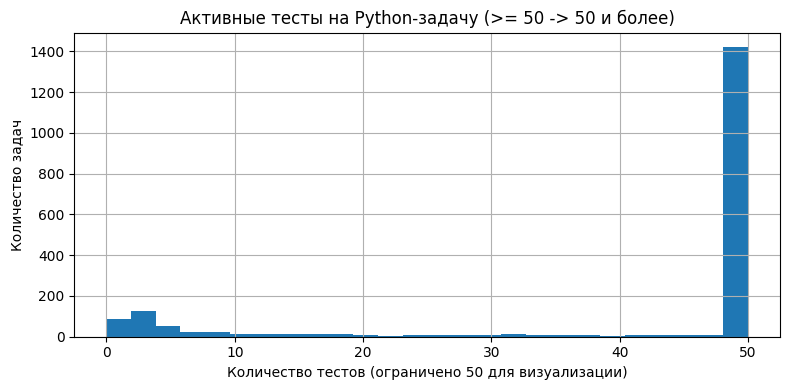

In [6]:
tests_by_problem = pd.read_sql_query(
    """
    WITH python_problems AS (
        SELECT DISTINCT problem_id
        FROM bugs
        WHERE language = 5 AND active = 1 AND split IN (0, 1, 2)
    )
    SELECT p.problem_id, COUNT(t.id) AS n_active_tests
    FROM python_problems AS p
    LEFT JOIN tests AS t
      ON t.problem_id = p.problem_id AND t.active = 1
    GROUP BY p.problem_id
    """,
    conn,
)
print("Python-задач:", len(tests_by_problem))
print(
    "Python-задач хотя бы с одним активным тестом:",
    int(tests_by_problem.n_active_tests.gt(0).sum()),
)
print(
    "Доля задач с тестами, %:",
    round(100 * tests_by_problem.n_active_tests.gt(0).mean(), 1)
    if len(tests_by_problem)
    else "нет данных",
)
print(
    "Количество задач без тестов:",
    len(tests_by_problem[tests_by_problem["n_active_tests"] == 0]),
)
display(
    tests_by_problem["n_active_tests"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .to_frame()
)

fig, ax = plt.subplots(figsize=(8, 4))
tests_by_problem["n_active_tests"].clip(upper=50).hist(ax=ax, bins=26)
ax.set_title("Активные тесты на Python-задачу (>= 50 -> 50 и более)")
ax.set_xlabel("Количество тестов (ограничено 50 для визуализации)")
ax.set_ylabel("Количество задач")
plt.tight_layout()
plt.show()

## 6. Размеры и сложность кода

Берём случайную выборку до 5000 строк. `token_count`, `hunk_count`, `change_count` — метаданные датасета.

,token_count,hunk_count,change_count,buggy_locs,buggy_chars
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,133.077800,1.428600,7.886400,15.813800,383.013400
std,125.035165,0.853843,7.142583,14.297427,454.503056
min,13.000000,1.000000,1.000000,1.000000,28.000000
50%,99.000000,1.000000,5.000000,12.000000,255.000000
75%,162.000000,2.000000,11.000000,20.000000,458.000000
90%,251.000000,2.000000,17.000000,30.000000,780.000000
95%,326.050000,3.000000,23.000000,39.000000,1071.050000
99%,562.010000,5.000000,34.000000,62.010000,1953.060000
max,2776.000000,12.000000,51.000000,328.000000,8654.000000


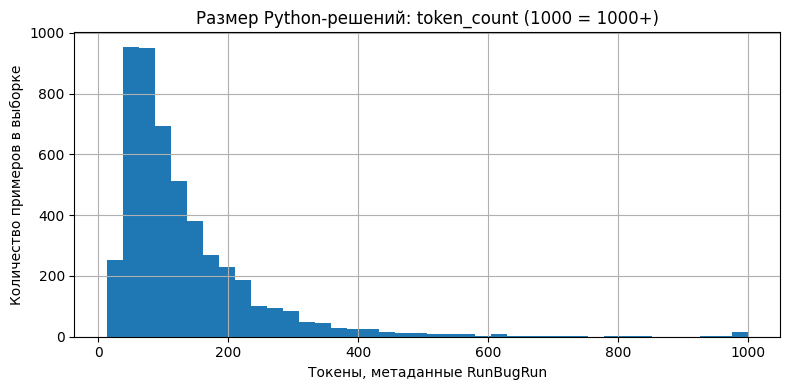

In [7]:
sample_stats = pd.read_sql_query(
    """
    SELECT id, problem_id, split, token_count,
    hunk_count, change_count,
    buggy_locs, fixed_locs,
    LENGTH(buggy_code) AS buggy_chars,
    LENGTH(fixed_code) AS fixed_chars
    FROM bugs
    WHERE language = 5 AND active = 1 AND split IN (0, 1, 2)
    ORDER BY RANDOM()
    LIMIT 5000
    """,
    conn,
)
cols = ["token_count", "hunk_count", "change_count", "buggy_locs", "buggy_chars"]
display(sample_stats[cols].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]))

fig, ax = plt.subplots(figsize=(8, 4))
sample_stats["token_count"].dropna().clip(upper=1000).hist(ax=ax, bins=40)
ax.set_title("Размер Python-решений: token_count (1000 = 1000+)")
ax.set_xlabel("Токены, метаданные RunBugRun")
ax.set_ylabel("Количество примеров в выборке")
plt.tight_layout()
plt.show()

## 7. Пересечение задач между сплитами

Если одна задача встречается и в train, и в test, подсказки могут оцениваться на уже встречавшихся условиях. Для строгой независимой оценки стоит проверить и при необходимости сделать отдельное разбиение **по problem_id**, не по строкам.

In [8]:
split_overlap = pd.read_sql_query(
    """
    WITH by_problem AS (
        SELECT problem_id,
        MAX(CASE WHEN split = 0 THEN 1 ELSE 0 END) AS in_train,
        MAX(CASE WHEN split = 1 THEN 1 ELSE 0 END) AS in_valid,
        MAX(CASE WHEN split = 2 THEN 1 ELSE 0 END) AS in_test
        FROM bugs
        WHERE language = 5 AND active = 1 AND split IN (0, 1, 2)
        GROUP BY problem_id
    )
    SELECT COUNT(*) AS n_problems,
    SUM(CASE WHEN in_train = 1 AND in_valid = 1 THEN 1 ELSE 0 END) AS train_valid,
    SUM(CASE WHEN in_train = 1 AND in_test = 1 THEN 1 ELSE 0 END) AS train_test,
    SUM(CASE WHEN in_valid = 1 AND in_test = 1 THEN 1 ELSE 0 END) AS valid_test
    FROM by_problem
    """,
    conn,
)
display(split_overlap)

,n_problems,train_valid,train_test,valid_test
0,1912,0,0,226


In [9]:
(
    split_overlap[["train_valid", "train_test", "valid_test"]]
    / split_overlap.loc[0, "n_problems"]
    * 100
).round(2).astype(str) + "%"

,train_valid,train_test,valid_test
0,0.0%,0.0%,11.82%


## 8. Посмотреть один полный пример

Выбираем активный Python-баг из train с непустым условием и активными тестами.

In [10]:
example_ids = pd.read_sql_query(
    """
    SELECT b.id, b.problem_id, b.split, b.token_count, b.hunk_count
    FROM bugs AS b
    JOIN problems AS p ON p.problem_id = b.problem_id
    WHERE b.language = 5 AND b.active = 1 AND b.split = 0
      AND LENGTH(TRIM(COALESCE(p.text, ''))) >= 30
      AND EXISTS (
          SELECT 1 FROM tests AS t
          WHERE t.problem_id = b.problem_id AND t.active = 1
      )
    LIMIT 3
    """,
    conn,
)
display(example_ids)


def preview(s, max_chars=1600):
    if s is None:
        return "<NULL>"
    s = str(s)
    return s[:max_chars] + (
        f"\n... [обрезано, всего {len(s)} символов]" if len(s) > max_chars else ""
    )


def inspect_example(bug_id):
    row = conn.execute(
        """SELECT id, problem_id, buggy_code, fixed_code, label_ids,
                  token_count, hunk_count, change_count
           FROM bugs WHERE id = ?""",
        (int(bug_id),),
    ).fetchone()
    if row is None:
        print("Не найден bug_id:", bug_id)
        return
    keys = [
        "id",
        "problem_id",
        "buggy_code",
        "fixed_code",
        "label_ids",
        "token_count",
        "hunk_count",
        "change_count",
    ]
    bug = dict(zip(keys, row, strict=False))
    text_row = conn.execute(
        "SELECT text FROM problems WHERE problem_id = ? LIMIT 1", (bug["problem_id"],)
    ).fetchone()
    print(
        f"BUG ID: {bug['id']} | problem_id: {bug['problem_id']} | labels: {bug['label_ids']}"
    )
    print("\nУСЛОВИЕ:\n", preview(text_row[0] if text_row else None))
    print("\nBUGGY CODE:\n", preview(bug["buggy_code"]))
    print("\nFIXED CODE:\n", preview(bug["fixed_code"]))
    cases = pd.read_sql_query(
        """SELECT test_id, input, output, origin FROM tests
           WHERE problem_id = ? AND active = 1 ORDER BY test_id LIMIT 3""",
        conn,
        params=(bug["problem_id"],),
    )
    for _, case in cases.iterrows():
        print(f"\nTEST {case['test_id']} (origin={case['origin']}):")
        print("stdin:\n", preview(case["input"], 400))
        print("expected stdout:\n", preview(case["output"], 400))


inspect_example(example_ids.iloc[0]["id"])

,id,problem_id,split,token_count,hunk_count
0,6587,p00000,0,38,1
1,6589,p00000,0,47,1
2,6590,p00000,0,37,1


BUG ID: 6587 | problem_id: p00000 | labels: [["+",8,196,0,1,0,652,3,4,0,21],["+",0,1,0,652,3,4,0,653,141,22],["+",0,1,0,652,3,4,0,653,0,32],["+",0,652,3,4,0,653,51,557,0,654],["+",0,652,3,4,0,653,51,557,0,655]]

УСЛОВИЕ:
 
QQ

Write a program which prints multiplication tables in the following format:


1x1=1
1x2=2
.
.
9x8=72
9x9=81

Input

No input.

Output

1x1=1
1x2=2
.
.
9x8=72
9x9=81

Template for C

#include<stdio.h>

int main(){

    return 0;
}

Template for C++

#include<iostream>
using namespace std;

int main(){

    return 0;
}

Template for Java

class Main{
    public static void main(String[] a){

    }
}


BUGGY CODE:
 for i in range(1,10):
    for j in range(1,10):
        print(i,"x",j,"=",i*j)

FIXED CODE:
 for i in range(1,10):
    for j in range(1,10):
        print(i,"x",j,"=",i*j,sep="")

TEST 126409 (origin=2):
stdin:
 
expected stdout:
 1x1=1
1x2=2
1x3=3
1x4=4
1x5=5
1x6=6
1x7=7
1x8=8
1x9=9
2x1=2
2x2=4
2x3=6
2x4=8
2x5=10
2x6=12
2x7=14
2x8=16
2x9=18
3x1=3
3x2=6
3

In [11]:
# Закрываем соединение, когда закончили анализ.
conn.close()
print("Соединение с SQLite закрыто")

Соединение с SQLite закрыто
